In [1]:
import pandas as pd
# Det her er en test
# Heeeej Viktor

## Load data
Energinet *ProductionConsumptionSettlement* (Energi Data Service), 2025, hourly, DK1 and DK2.  
The file uses `;` as separator and `,` as decimal mark.

In [2]:
df = pd.read_csv("ProductionConsumptionSettlement.csv", sep=";", decimal=",",
                 parse_dates=["HourUTC", "HourDK"])
df = df.sort_values(["HourUTC", "PriceArea"]).reset_index(drop=True)  # file is sorted newest first


df.drop(columns=["PriceArea","CentralPowerMWh","LocalPowerMWh","CommercialPowerMWh","LocalPowerSelfConMWh","HydroPowerMWh","ExchangeSE_MWh", "ExchangeGE_MWh"], inplace=True)  # drop columns that are not needed
df.head()

,HourUTC,HourDK,OffshoreWindLt100MW_MWh,OffshoreWindGe100MW_MWh,OnshoreWindLt50kW_MWh,OnshoreWindGe50kW_MWh,SolarPowerLt10kW_MWh,SolarPowerGe10Lt40kW_MWh,SolarPowerGe40kW_MWh,SolarPowerSelfConMWh,UnknownProdMWh,ExchangeNO_MWh,ExchangeNL_MWh,ExchangeGB_MWh,ExchangeGreatBelt_MWh,GrossConsumptionMWh,GridLossTransmissionMWh,GridLossInterconnectorsMWh,GridLossDistributionMWh,PowerToHeatMWh
0,2024-12-31 23:00:00,2025-01-01 00:00:00,221.271215,1285.866796,14.123306,3269.386618,0.167449,0.055958,0.050220,0.0,0.145240,-1663.5741,-353.196,16.253469,-447.8,3068.153442,112.352214,62.3851,140.275622,824.219887
1,2024-12-31 23:00:00,2025-01-01 00:00:00,33.201800,897.953218,1.632528,601.122276,0.117938,0.022880,0.054689,0.0,2.745074,NaN,NaN,NaN,440.9,1684.124812,58.937666,1.9660,82.700911,139.791053
2,2025-01-01 00:00:00,2025-01-01 01:00:00,216.368038,1163.784669,13.996072,3235.545640,0.170201,0.054554,0.055574,0.0,0.307740,-1663.7999,-682.743,-250.274511,-457.8,3024.472823,119.134226,74.0599,138.148259,774.421902
3,2025-01-01 00:00:00,2025-01-01 01:00:00,26.030700,511.022869,1.680799,600.363627,0.123022,0.020321,0.011923,0.0,1.477600,NaN,NaN,NaN,450.7,1671.470494,44.998340,5.4900,82.648678,132.188810
4,2025-01-01 01:00:00,2025-01-01 02:00:00,73.050699,1025.820909,13.752589,3192.651473,0.151677,0.048444,0.051820,0.0,0.010471,-1641.8612,-111.974,-414.861463,16.8,3058.092913,98.579314,56.1772,137.748688,848.708904


## Simplified national time series (`df_simplyfi`)
Project guideline step 2: DK1 and DK2 contributions are added, so there is one row per hour for the whole of Denmark.  
We group on `HourUTC` because `HourDK` has a duplicated/missing hour at the daylight-saving shifts.

In [3]:
wind_cols = ["OffshoreWindLt100MW_MWh", "OffshoreWindGe100MW_MWh",
             "OnshoreWindLt50kW_MWh", "OnshoreWindGe50kW_MWh"]
solar_cols = ["SolarPowerLt10kW_MWh", "SolarPowerGe10Lt40kW_MWh",
              "SolarPowerGe40kW_MWh"]  # SolarPowerGe10kW_MWh is the sum of the two previous columns, but we include it for completeness

df["Wind_MWh"] = df[wind_cols].sum(axis=1)
df["Solar_MWh"] = df[solar_cols].sum(axis=1)

# Sum DK1 + DK2 for every hour
df_simplyfi = (df.groupby("HourUTC", as_index=False)
                 .agg(HourDK=("HourDK", "first"),
                      Wind_MWh=("Wind_MWh", "sum"),
                      Solar_MWh=("Solar_MWh", "sum"),
                      GrossConsumption_MWh=("GrossConsumptionMWh", "sum")))

df_simplyfi.drop(columns=["HourDK"], inplace=True)  # drop HourDK, as it is not unique for DK1+DK2
df_simplyfi.head()

,HourUTC,Wind_MWh,Solar_MWh,GrossConsumption_MWh
0,2024-12-31 23:00:00,6324.557757,0.469134,4752.278254
1,2025-01-01 00:00:00,5768.792414,0.435595,4695.943317
2,2025-01-01 01:00:00,5109.470665,0.397615,4635.561834
3,2025-01-01 02:00:00,5027.957554,0.404335,4605.831495
4,2025-01-01 03:00:00,5257.804306,0.646446,4446.709225


## Future demand profile
Today's gross consumption is standardised (divided by its own mean, so the profile has mean = 1) and used for the hourly fluctuations of **households + light transport**.
**Industry** and **heavy transport** are constant every hour.

Note: transport is counted as its fuel energy (guideline step 1), not converted to EV electricity.

In [4]:
PJ_TO_MWH = 1e15 / 3.6e9        # 1 PJ = 277 777.8 MWh
n_hours = len(df_simplyfi)      # 8736 (31 Dec 2025 is missing in the CSV)

# Annual demand, guideline step 1 (PJ/year)
households_PJ      = 300
light_transport_PJ = 100        # NB: fuel energy - not yet converted to EV electricity
industry_PJ        = 150 + 30   # incl. 30 PJ data centres
heavy_transport_PJ = 50 + 50 + 50   # trucks + shipping + aviation

# 1) Standardised profile: today's gross consumption / its own mean  (mean = 1)
df_simplyfi["profile"] = (df_simplyfi["GrossConsumption_MWh"]
                          / df_simplyfi["GrossConsumption_MWh"].mean())

# 2) Households + light transport follow the profile
mean_hh_lt_MWh = (households_PJ + light_transport_PJ) * PJ_TO_MWH / n_hours
df_simplyfi["HouseholdsLight_MWh"] = df_simplyfi["profile"] * mean_hh_lt_MWh

# 3) Industry and heavy transport: constant every hour
df_simplyfi["Industry_MWh"]       = industry_PJ * PJ_TO_MWH / n_hours
df_simplyfi["HeavyTransport_MWh"] = heavy_transport_PJ * PJ_TO_MWH / n_hours

df_simplyfi["Demand_MWh"] = (df_simplyfi["HouseholdsLight_MWh"]
                             + df_simplyfi["Industry_MWh"]
                             + df_simplyfi["HeavyTransport_MWh"])

# Check: annual totals in PJ
print(df_simplyfi[["HouseholdsLight_MWh", "Industry_MWh",
                   "HeavyTransport_MWh", "Demand_MWh"]].sum() / PJ_TO_MWH)
print(f"Mean households+light: {mean_hh_lt_MWh/1e3:.2f} GW "
      f"(today's gross mean: {df_simplyfi['GrossConsumption_MWh'].mean()/1e3:.2f} GW)")

HouseholdsLight_MWh    400.0
Industry_MWh           180.0
HeavyTransport_MWh     150.0
Demand_MWh             730.0
dtype: float64
Mean households+light: 12.72 GW (today's gross mean: 4.62 GW)


## Supply: scaled wind + solar and constant biomass
Wind and solar are scaled with the same factor (ratio kept) to 730 PJ − biomass.
Biomass is used evenly over the year (same power every hour). Assumption: 1 PJ biomass = 1 PJ electricity (no conversion losses).

In [5]:
Total_PJ   = 730
Biomass_PJ = 200    # slides say 200 PJ, written guidelines 2026 say 150 PJ -> decide!

production_target_PJ = Total_PJ - Biomass_PJ
production_2025_PJ = (df_simplyfi["Wind_MWh"].sum()
                      + df_simplyfi["Solar_MWh"].sum()) / PJ_TO_MWH
scaling_factor = production_target_PJ / production_2025_PJ

df_simplyfi["ideal_Wind_MWh"]  = scaling_factor * df_simplyfi["Wind_MWh"]
df_simplyfi["ideal_Solar_MWh"] = scaling_factor * df_simplyfi["Solar_MWh"]
df_simplyfi["Production_MWh"]  = df_simplyfi["ideal_Wind_MWh"] + df_simplyfi["ideal_Solar_MWh"]

df_simplyfi["Biomass_MWh"] = Biomass_PJ * PJ_TO_MWH / n_hours   # constant every hour
df_simplyfi["Supply_MWh"]  = df_simplyfi["Production_MWh"] + df_simplyfi["Biomass_MWh"]
df_simplyfi["Prosumption_MWh"] = df_simplyfi["Supply_MWh"] - df_simplyfi["Demand_MWh"]

pros = df_simplyfi["Prosumption_MWh"]
print(f"Scaling factor wind + solar: {scaling_factor:.2f}")
print(f"Biomass: {df_simplyfi['Biomass_MWh'].iloc[0]/1e3:.2f} GW every hour")
print(f"Annual prosumption: {pros.sum()/PJ_TO_MWH:.1f} PJ (should be 0)")
print(f"  surplus hours: {pros.clip(lower=0).sum()/PJ_TO_MWH:.1f} PJ, "
      f"deficit hours: {pros.clip(upper=0).sum()/PJ_TO_MWH:.1f} PJ, "
      f"{(pros > 0).sum()} of {n_hours} hours with surplus")

# Monthly balance (PJ)
month = (df_simplyfi["HourUTC"] + pd.Timedelta(hours=1)).dt.month
monthly = (df_simplyfi.groupby(month)[["Production_MWh", "Biomass_MWh", "Supply_MWh",
                                       "Demand_MWh", "Prosumption_MWh"]].sum() / PJ_TO_MWH)
monthly.loc["Year"] = monthly.sum()
monthly.round(1)

Scaling factor wind + solar: 6.37
Biomass: 6.36 GW every hour
Annual prosumption: 0.0 PJ (should be 0)
  surplus hours: 123.2 PJ, deficit hours: -123.2 PJ, 4156 of 8736 hours with surplus


,Production_MWh,Biomass_MWh,Supply_MWh,Demand_MWh,Prosumption_MWh
HourUTC,,,,,
1,50.3,17.0,67.3,66.6,0.7
2,36.9,15.4,52.3,59.8,-7.6
3,47.2,17.0,64.3,63.7,0.6
4,30.5,16.5,46.9,58.2,-11.3
5,46.0,17.0,63.0,60.4,2.6
6,50.2,16.5,66.7,57.2,9.5
7,37.9,17.0,55.0,56.8,-1.8
8,40.8,17.0,57.8,58.9,-1.1
9,45.8,16.5,62.3,58.4,3.9


## Figure 1 – supply vs. demand per month

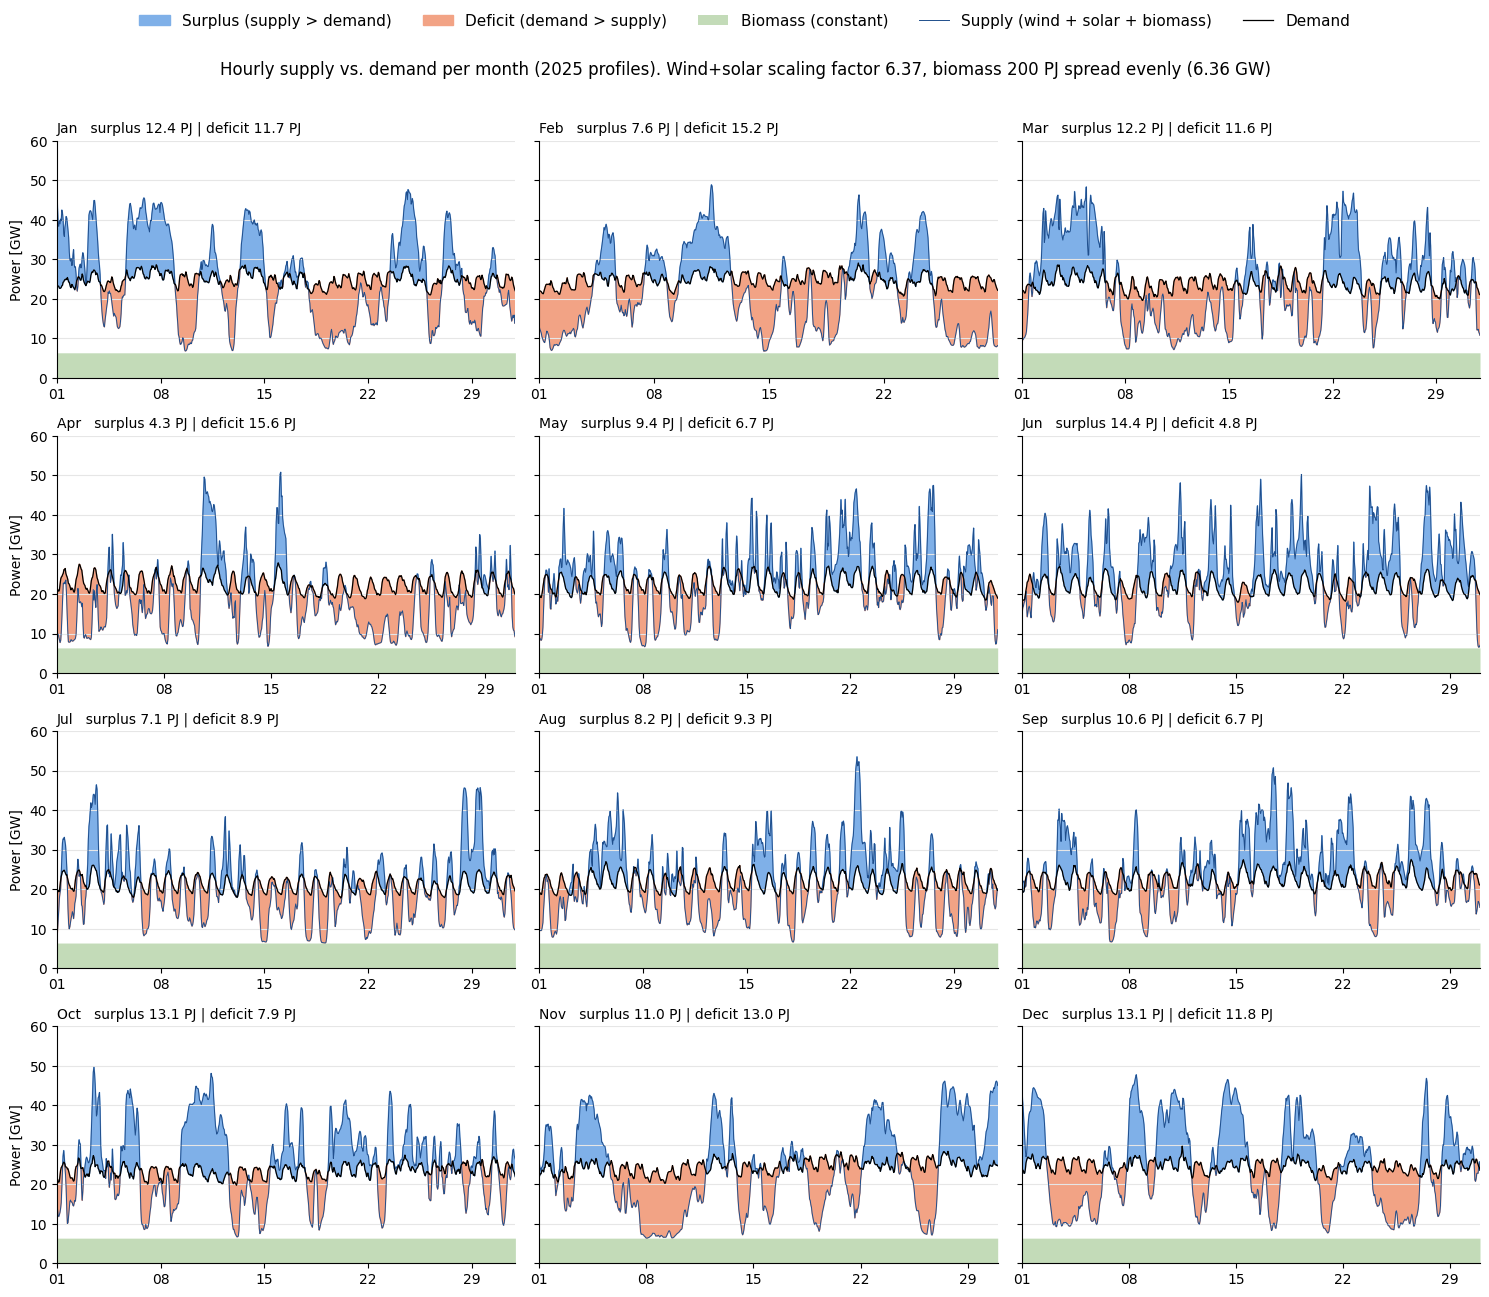

In [6]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

t      = df_simplyfi["HourUTC"] + pd.Timedelta(hours=1)   # ~Danish time (CET)
supply = df_simplyfi["Supply_MWh"] / 1e3                  # GW
dem    = df_simplyfi["Demand_MWh"] / 1e3
bio    = df_simplyfi["Biomass_MWh"] / 1e3
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
ymax = np.ceil(supply.max() / 10) * 10                    # same y-axis in all panels

fig, axes = plt.subplots(4, 3, figsize=(15, 13), sharey=True)
for m, ax in enumerate(axes.flat, start=1):
    sel = t.dt.month == m
    x, s, d = t[sel], supply[sel], dem[sel]
    ax.fill_between(x, s, d, where=s >= d, interpolate=True, color="#7FB0E8",
                    label="Surplus (supply > demand)")
    ax.fill_between(x, s, d, where=s < d, interpolate=True, color="#F2A385",
                    label="Deficit (demand > supply)")
    ax.fill_between(x, 0, bio[sel], color="#9BC48A", alpha=0.6, lw=0,
                    label="Biomass (constant)")
    ax.plot(x, s, color="#1F4E8C", lw=0.7, label="Supply (wind + solar + biomass)")
    ax.plot(x, d, color="black", lw=0.9, label="Demand")

    p = df_simplyfi.loc[sel, "Prosumption_MWh"]
    surplus = p.clip(lower=0).sum() / PJ_TO_MWH
    deficit = -p.clip(upper=0).sum() / PJ_TO_MWH
    ax.set_title(f"{months[m-1]}   surplus {surplus:.1f} PJ | deficit {deficit:.1f} PJ",
                 fontsize=10, loc="left")
    ax.set_xlim(x.min(), x.max()); ax.set_ylim(0, ymax)
    ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22, 29]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d"))
    ax.grid(axis="y", color="0.9")
    ax.spines[["top", "right"]].set_visible(False)
    if (m - 1) % 3 == 0:
        ax.set_ylabel("Power [GW]")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, frameon=False, fontsize=11)
fig.suptitle(f"Hourly supply vs. demand per month (2025 profiles). "
             f"Wind+solar scaling factor {scaling_factor:.2f}, "
             f"biomass {Biomass_PJ} PJ spread evenly ({bio.iloc[0]:.2f} GW)",
             y=0.955, fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.945])
plt.savefig("Figure1_monthly_production_demand.png", dpi=300)
plt.show()